# Principal component analysis (PCA), and the anomalies a 2-D plot cannot show

Aurora's data team hands over 2,000 accounts with 8 columns each: spend,
basket size, purchase frequency, discount usage, days since the last purchase,
weekend share, mobile sessions, return rate. Hidden in `retail_data.py`, and
withheld from every method below, is the fact that only **three** underlying
tendencies drive all eight columns, and that 40 of the accounts were taken
over by fraudsters.

This notebook builds the idea of **principal component analysis (PCA)** on
two columns, where it can be drawn, then uses it on all eight to find how
many numbers really vary, and to catch the fraudulent accounts. The last
section shows why a 2-D scatter plot, the natural first thing to try, is the
wrong tool for that last job. The handout's sections 4 and 5 tell the same
story in prose.

## 1. Setup

In [1]:
# pip install numpy==1.26.4 pandas==2.1.1 matplotlib==3.8.0 scikit-learn==1.3.1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

from retail_data import make_customer_features, TRUE_N_LATENT_FACTORS

FIGURES = Path.cwd().parent / "Figures"
FIGURES.mkdir(exist_ok=True)

BLUE, TEAL, RUST, GOLD, GREY, INK = "#1F4E79", "#2E8B8B", "#B4483E", "#C9A227", "#B0B0B0", "#1A1A1A"

accounts = make_customer_features()
feature_names = [c for c in accounts.columns if c != "is_anomaly"]
X = accounts[feature_names].values
Xs = StandardScaler().fit_transform(X)
is_anomaly = accounts["is_anomaly"].values

print(f"{len(accounts)} accounts, {len(feature_names)} columns; "
      f"{is_anomaly.sum()} planted anomalies (kept aside: no method below sees them)")
accounts.head()

2000 accounts, 8 columns; 40 planted anomalies (kept aside: no method below sees them)


,annual_spend_eur,avg_basket_value_eur,purchase_frequency,discount_usage_rate,days_since_last_purchase,weekend_purchase_ratio,mobile_session_count,return_rate,is_anomaly
0,416.463147,59.371566,4.213978,0.304835,32.927178,0.328674,4.822756,0.052241,False
1,189.883176,26.776158,5.302197,0.449134,28.772730,0.379814,10.064287,0.053112,False
2,598.305514,51.755406,5.496863,0.480950,26.713322,0.473879,12.624603,0.076102,False
3,375.504530,51.844814,7.318414,0.264960,22.392302,0.475562,12.487982,0.049747,False
4,577.093989,67.839496,-1.338149,0.219413,44.413437,0.046023,0.000000,0.017944,False


## 2. Eight columns, not eight independent numbers

If the eight columns were unrelated, none could be dropped without losing
information. They are not: spend, basket value and mobile sessions all rise
together, because all three partly reflect how much a customer likes to spend.
The correlation matrix shows it before any PCA runs.

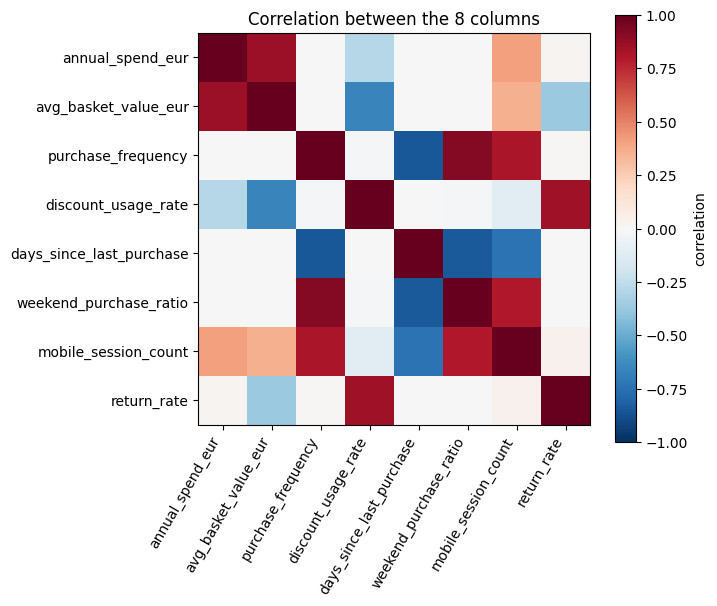

correlation of annual spend with average basket value: 0.859


In [2]:
corr = pd.DataFrame(Xs, columns=feature_names).corr()

fig, ax = plt.subplots(figsize=(7.2, 6.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_names))); ax.set_xticklabels(feature_names, rotation=60, ha="right")
ax.set_yticks(range(len(feature_names))); ax.set_yticklabels(feature_names)
fig.colorbar(im, ax=ax, label="correlation")
ax.set_title("Correlation between the 8 columns")
fig.tight_layout()
fig.savefig(FIGURES / "feature_correlation.png", dpi=150)
plt.show()

print(f"correlation of annual spend with average basket value: {corr.iloc[0, 1]:.3f}")

## 3. The idea on two columns: the direction with the widest shadow

Take just two of the columns, annual spend and average basket value, both
standardised (mean 0, standard deviation 1). Their correlation is 0.859: the
points lie along a tilted band.

Pick any direction through the middle of the cloud and drop every point onto
it at a right angle, like a shadow cast on a line. Each shadow is one number
per account: a one-number summary of the two columns. Some directions spread
the shadows widely, others squash them together. A summary that keeps the
accounts apart keeps the information that tells them apart, so the best
one-number summary is the direction where **the shadows spread the most**,
measured by their variance. That direction is the **first principal
component**. The second is the direction at right angles to it.

Measure the spread of the shadows for every direction from 0° (the spend axis)
to 180°.

In [3]:
pair = Xs[:, :2]                               # spend and basket value, standardised
r = np.corrcoef(pair.T)[0, 1]

angles = np.arange(0, 181)
shadow_variance = []
for deg in angles:
    u = np.array([np.cos(np.radians(deg)), np.sin(np.radians(deg))])   # a direction of length 1
    shadows = pair @ u                         # one number per account: its shadow on that direction
    shadow_variance.append(shadows.var())
shadow_variance = np.array(shadow_variance)

best, worst = angles[shadow_variance.argmax()], angles[shadow_variance.argmin()]
print(f"spread of the shadows on the spend axis (0 degrees): {shadow_variance[0]:.3f}")
print(f"widest  at {best:>3} degrees: variance {shadow_variance.max():.3f}   (1 + r = {1 + r:.3f})")
print(f"narrowest at {worst:>3} degrees: variance {shadow_variance.min():.3f}   (1 - r = {1 - r:.3f})")

spread of the shadows on the spend axis (0 degrees): 1.000
widest  at  45 degrees: variance 1.859   (1 + r = 1.859)
narrowest at 135 degrees: variance 0.141   (1 - r = 0.141)


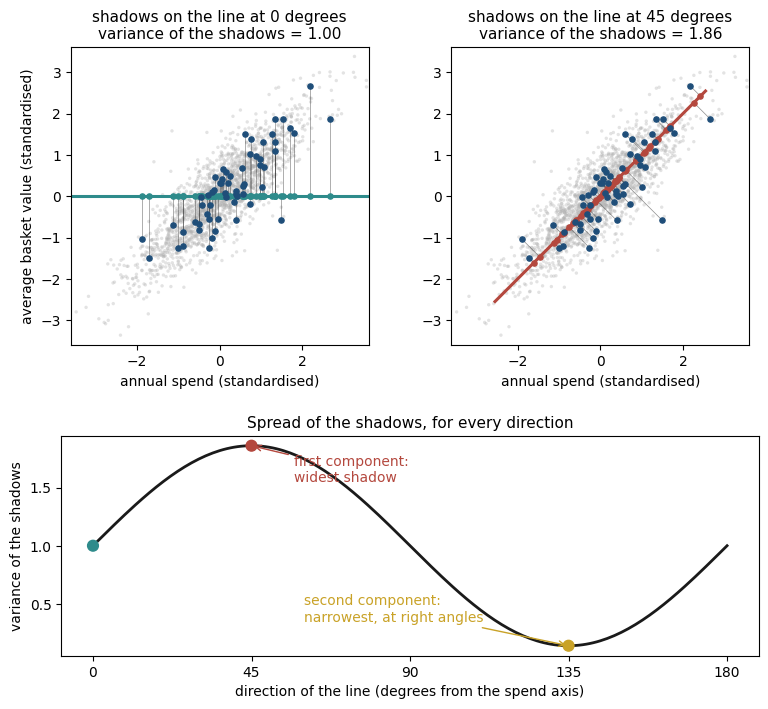

In [4]:
rng = np.random.default_rng(0)
show = rng.choice(len(pair), 60, replace=False)          # 60 accounts, so each shadow can be seen

fig = plt.figure(figsize=(9.0, 7.9))
grid = fig.add_gridspec(2, 2, height_ratios=[1.15, 0.85], hspace=.35)
axes = [fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1]), fig.add_subplot(grid[1, :])]
for ax, deg, colour in ((axes[0], 0, TEAL), (axes[1], best, RUST)):
    u = np.array([np.cos(np.radians(deg)), np.sin(np.radians(deg))])
    ax.scatter(pair[:, 0], pair[:, 1], s=6, color=GREY, alpha=.35, edgecolor="none")
    t = np.linspace(-3.6, 3.6, 2)
    ax.plot(t * u[0], t * u[1], color=colour, lw=2.2)
    for p in pair[show]:
        foot = u * (p @ u)
        ax.plot([p[0], foot[0]], [p[1], foot[1]], color=INK, lw=.5, alpha=.5)
        ax.scatter(*foot, s=14, color=colour, zorder=3)
    ax.scatter(*pair[show].T, s=14, color=BLUE, zorder=3)
    ax.set_xlim(-3.6, 3.6); ax.set_ylim(-3.6, 3.6); ax.set_aspect("equal")
    ax.set_xlabel("annual spend (standardised)")
    ax.set_title(f"shadows on the line at {deg} degrees\nvariance of the shadows = {shadow_variance[deg]:.2f}", fontsize=11)
axes[0].set_ylabel("average basket value (standardised)")

ax = axes[2]
ax.plot(angles, shadow_variance, color=INK, lw=2)
ax.scatter([0, best, worst], shadow_variance[[0, best, worst]], s=60, color=[TEAL, RUST, GOLD], zorder=3)
ax.annotate("first component:\nwidest shadow", (best, shadow_variance[best]), (best + 12, 1.55),
            arrowprops=dict(arrowstyle="->", color=RUST), color=RUST, fontsize=10)
ax.annotate("second component:\nnarrowest, at right angles", (worst, shadow_variance[worst]), (60, 0.35),
            arrowprops=dict(arrowstyle="->", color=GOLD), color=GOLD, fontsize=10)
ax.set_xticks(range(0, 181, 45))
ax.set_xlabel("direction of the line (degrees from the spend axis)")
ax.set_ylabel("variance of the shadows")
ax.set_title("Spread of the shadows, for every direction", fontsize=11)
fig.savefig(FIGURES / "pca_shadow.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

The shadows spread most along the diagonal at 45°, where spend and basket
value rise together, with variance $1 + r = 1.859$; they spread least at 135°,
across the band, with variance $1 - r = 0.141$. On the spend axis alone the
variance is 1, as it must be for a standardised column.

That the answer is exactly $1 + r$ and $1 - r$ is no accident, and the handout
(section 4.2) shows the two lines of algebra behind it. In general, with any
number of columns, the same search has a ready-made answer from linear algebra:
**the principal components are the eigenvectors of the covariance matrix, and
each one's eigenvalue is the variance of the shadows along it.** We take that
as stated, and check it here against both the angle search and scikit-learn.

In [5]:
cov = np.cov(pair.T, bias=True)                          # covariance, dividing by m like .var() above
eigenvalues, eigenvectors = np.linalg.eigh(cov)
order = eigenvalues.argsort()[::-1]
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
print("covariance matrix:\n", cov.round(3))
print("eigenvalues:", eigenvalues.round(3), "  first eigenvector:", np.abs(eigenvectors[:, 0]).round(3),
      f"(the 45-degree direction: cos 45 = {np.cos(np.radians(45)):.3f})")

pca2 = PCA(n_components=2).fit(pair)
print("scikit-learn PCA, share of the variance per component:", pca2.explained_variance_ratio_.round(4))
print(f"the same from the shadows: {shadow_variance.max() / 2:.4f} and {shadow_variance.min() / 2:.4f}"
      "  (each variance divided by the total, 1 + 1 = 2)")

covariance matrix:
 [[1.    0.859]
 [0.859 1.   ]]
eigenvalues: [1.859 0.141]   first eigenvector: [0.707 0.707] (the 45-degree direction: cos 45 = 0.707)
scikit-learn PCA, share of the variance per component: [0.9297 0.0703]
the same from the shadows: 0.9297 and 0.0703  (each variance divided by the total, 1 + 1 = 2)


Three routes, one answer. The first component alone carries 93% of the
variance of the two columns: one number per account (its shadow on the
diagonal) summarises both columns almost completely.

## 4. All eight columns: how many components?

PCA on all eight standardised columns. `explained_variance_ratio_` gives each
component's share of the total variance, largest first. The **scree plot**
draws those shares; look for where they stop mattering.

In [6]:
pca = PCA().fit(Xs)
ratio = pca.explained_variance_ratio_
cumulative = ratio.cumsum()
for i, (one, up_to) in enumerate(zip(ratio, cumulative), start=1):
    print(f"component {i}: {one:6.1%} of the variance   first {i} together: {up_to:6.1%}")

component 1:  44.2% of the variance   first 1 together:  44.2%
component 2:  32.1% of the variance   first 2 together:  76.3%
component 3:  17.2% of the variance   first 3 together:  93.5%
component 4:   2.4% of the variance   first 4 together:  96.0%
component 5:   1.3% of the variance   first 5 together:  97.3%
component 6:   1.2% of the variance   first 6 together:  98.5%
component 7:   1.0% of the variance   first 7 together:  99.5%
component 8:   0.5% of the variance   first 8 together: 100.0%


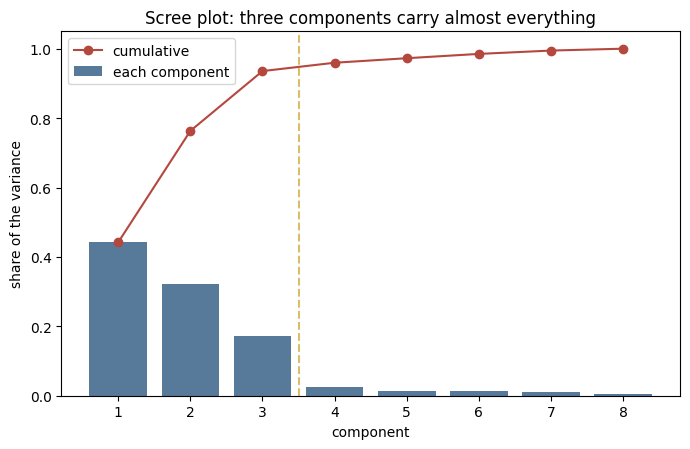

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.bar(range(1, len(ratio) + 1), ratio, color=BLUE, alpha=.75, label="each component")
ax.plot(range(1, len(cumulative) + 1), cumulative, "o-", color=RUST, label="cumulative")
ax.axvline(TRUE_N_LATENT_FACTORS + 0.5, color=GOLD, linestyle="--", alpha=.7)
ax.set_xlabel("component"); ax.set_ylabel("share of the variance")
ax.set_title("Scree plot: three components carry almost everything")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "pca_scree.png", dpi=150)
plt.show()

Three components carry 93.5% of the variance; the fourth adds 2.4%. The
plot has recovered, from the data alone, the number this notebook withheld:
three tendencies drive the eight columns. Real data is rarely this clean, and
the gap is this sharp only because `retail_data.py` built it in; but the
reading is the same: keep the components before the drop.

## 5. Fraudulent accounts: every value ordinary, the combination not

The 40 planted anomalies are accounts taken over by fraudsters. For each
column, `retail_data.py` drew the fraudulent value at random from inside the
range genuine accounts occupy, between their 5th and 95th percentiles, and
independently of the other columns. So no single column gives them away.

In [8]:
genuine = accounts.loc[~is_anomaly, feature_names]
fraud = accounts.loc[is_anomaly, feature_names]
low, high = genuine.quantile(0.05), genuine.quantile(0.95)
inside = ((fraud >= low) & (fraud <= high)).mean()
print("share of the 40 anomalies inside the genuine 5th-95th percentile range, column by column:")
print(inside.round(3).to_string())

share of the 40 anomalies inside the genuine 5th-95th percentile range, column by column:
annual_spend_eur            1.0
avg_basket_value_eur        1.0
purchase_frequency          1.0
discount_usage_rate         1.0
days_since_last_purchase    1.0
weekend_purchase_ratio      1.0
mobile_session_count        1.0
return_rate                 1.0


Every value of every anomaly is inside the ordinary range. What the
fraudster could not copy is how the columns move *together*: a genuine
account with a high spend also has a large basket, because one tendency drives
both. Drawn on the two columns of section 3, the anomalies fall off the band.

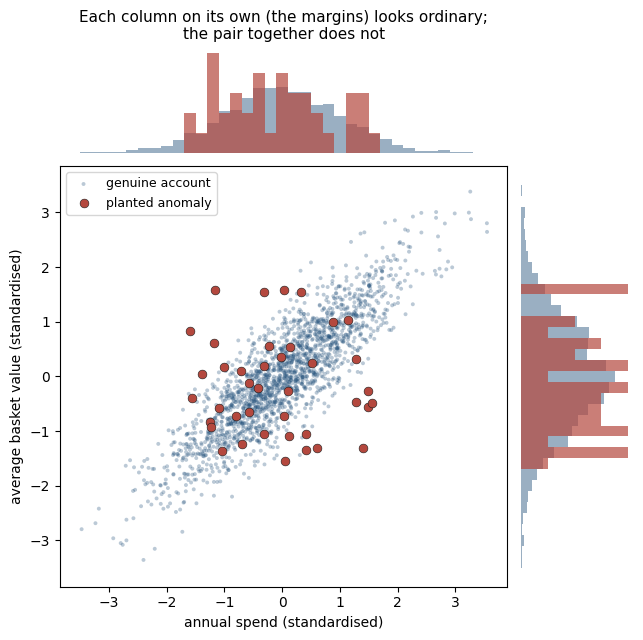

In [9]:
fig = plt.figure(figsize=(7.4, 7.0))
grid = fig.add_gridspec(2, 2, width_ratios=[4, 1], height_ratios=[1, 4], hspace=.05, wspace=.05)
ax = fig.add_subplot(grid[1, 0])
top = fig.add_subplot(grid[0, 0], sharex=ax)
side = fig.add_subplot(grid[1, 1], sharey=ax)
ax.scatter(*pair[~is_anomaly].T, s=8, color=BLUE, alpha=.3, edgecolor="none", label="genuine account")
ax.scatter(*pair[is_anomaly].T, s=40, color=RUST, edgecolor=INK, linewidth=.4, label="planted anomaly")
ax.set_xlabel("annual spend (standardised)"); ax.set_ylabel("average basket value (standardised)")
ax.legend(fontsize=9, loc="upper left")
bins = np.linspace(-3.5, 3.5, 36)
for col, axis, orient in ((0, top, "vertical"), (1, side, "horizontal")):
    axis.hist(pair[~is_anomaly, col], bins=bins, color=BLUE, alpha=.45, density=True, orientation=orient)
    axis.hist(pair[is_anomaly, col], bins=bins, color=RUST, alpha=.7, density=True, orientation=orient)
    axis.axis("off")
top.set_title("Each column on its own (the margins) looks ordinary;\nthe pair together does not", fontsize=11)
fig.savefig(FIGURES / "anomalies_off_the_band.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

## 6. Reconstruction error

Keep only the first component of the two columns, and ask each account to be
rebuilt from its shadow alone: the **reconstruction** is the point on the line
where the shadow fell. For an account that follows the band, the rebuilt point
is close to the real one. For an account off the band, it is far. The squared
distance between an account and its reconstruction is its **reconstruction
error**.

`PCA.transform` computes the shadows, `PCA.inverse_transform` puts them back
on the line in the original columns.

In [10]:
pca1 = PCA(n_components=1).fit(pair)
rebuilt = pca1.inverse_transform(pca1.transform(pair))
error2 = ((pair - rebuilt) ** 2).sum(axis=1)
print(f"mean reconstruction error from one component, genuine accounts: {error2[~is_anomaly].mean():.3f}")
print(f"mean reconstruction error from one component, anomalies:        {error2[is_anomaly].mean():.3f}")

# One account of each kind to draw: the genuine account farthest along the band,
# and the anomaly farthest from it.
far_genuine = np.flatnonzero(~is_anomaly)[np.abs(pca1.transform(pair[~is_anomaly])[:, 0]).argmax()]
far_anomaly = np.flatnonzero(is_anomaly)[error2[is_anomaly].argmax()]
for name, i in (("genuine, far along the band", far_genuine), ("anomaly, off the band", far_anomaly)):
    print(f"{name:<28} distance from the middle {np.linalg.norm(pair[i]):.2f}   reconstruction error {error2[i]:.2f}")

mean reconstruction error from one component, genuine accounts: 0.126
mean reconstruction error from one component, anomalies:        0.859
genuine, far along the band  distance from the middle 4.70   reconstruction error 0.01
anomaly, off the band        distance from the middle 1.96   reconstruction error 3.75


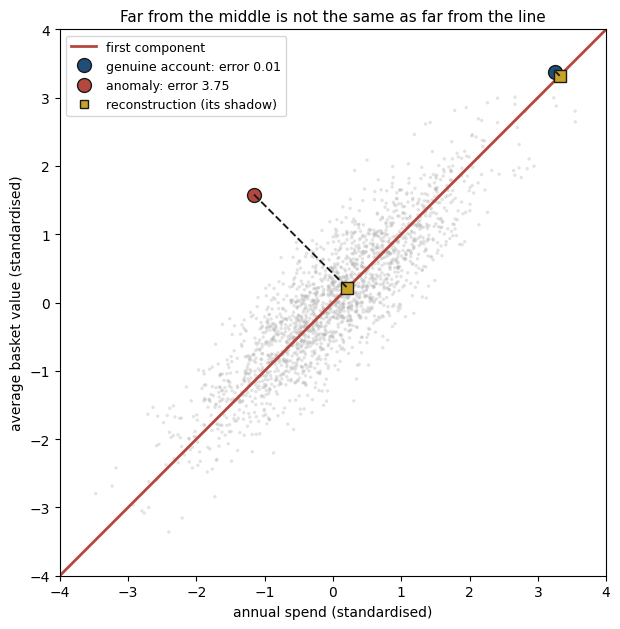

In [11]:
fig, ax = plt.subplots(figsize=(7.4, 6.4))
ax.scatter(*pair[~is_anomaly].T, s=6, color=GREY, alpha=.35, edgecolor="none")
u = pca1.components_[0]
t = np.linspace(-6, 6, 2)                     # long enough to cross the whole plot
ax.plot(t * u[0], t * u[1], color=RUST, lw=2, label="first component")
for i, colour, name in ((far_genuine, BLUE, "genuine account"), (far_anomaly, RUST, "anomaly")):
    ax.plot(*pair[i], "o", color=colour, markersize=10, markeredgecolor=INK,
            label=f"{name}: error {error2[i]:.2f}")
    ax.plot(*rebuilt[i], "s", color=GOLD, markersize=9, markeredgecolor=INK)
    ax.plot([pair[i, 0], rebuilt[i, 0]], [pair[i, 1], rebuilt[i, 1]], "--", color=INK, lw=1.4)
ax.plot([], [], "s", color=GOLD, markeredgecolor=INK, label="reconstruction (its shadow)")
ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal")
ax.set_xlabel("annual spend (standardised)"); ax.set_ylabel("average basket value (standardised)")
ax.set_title("Far from the middle is not the same as far from the line", fontsize=11)
ax.legend(fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "reconstruction_two_columns.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

The genuine account is the farthest from the middle of the two, yet its
error is tiny: it sits on the band, so its shadow says almost everything about
it. The anomaly is closer to the middle, and its error is large: the band
cannot describe it. That is the whole detector. In eight columns the "line"
becomes the three-component space found in section 4, and an account is
suspicious when those three components cannot rebuild it.

In [12]:
pca3 = PCA(n_components=TRUE_N_LATENT_FACTORS).fit(Xs)
rebuilt8 = pca3.inverse_transform(pca3.transform(Xs))
error = ((Xs - rebuilt8) ** 2).sum(axis=1)

threshold = np.quantile(error, 0.98)          # flag the 2% of accounts that rebuild worst
flagged = error > threshold
caught = int((flagged & is_anomaly).sum())
print(f"threshold (98th percentile of the reconstruction error): {threshold:.3f}")
print(f"flagged {flagged.sum()} accounts; {caught} of {is_anomaly.sum()} planted anomalies among them")
print(f"mean reconstruction error: anomalies {error[is_anomaly].mean():.3f}, genuine {error[~is_anomaly].mean():.3f}")

threshold (98th percentile of the reconstruction error): 2.019
flagged 40 accounts; 37 of 40 planted anomalies among them
mean reconstruction error: anomalies 4.676, genuine 0.431


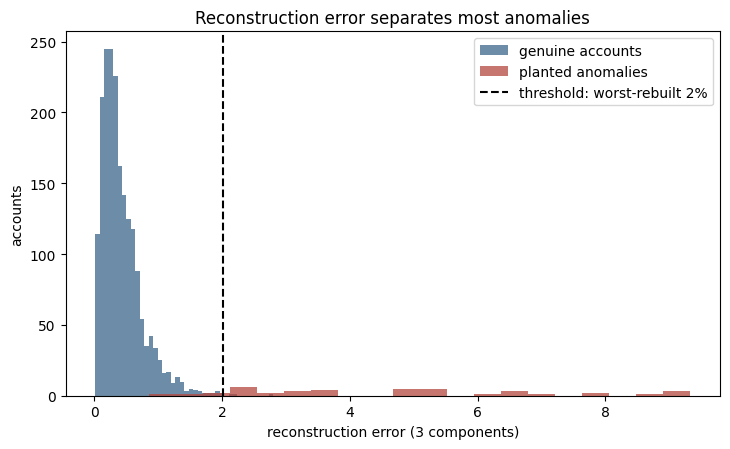

In [13]:
fig, ax = plt.subplots(figsize=(7.4, 4.6))
ax.hist(error[~is_anomaly], bins=40, color=BLUE, alpha=.65, label="genuine accounts")
ax.hist(error[is_anomaly], bins=20, color=RUST, alpha=.75, label="planted anomalies")
ax.axvline(threshold, color="black", linestyle="--", label="threshold: worst-rebuilt 2%")
ax.set_xlabel("reconstruction error (3 components)"); ax.set_ylabel("accounts")
ax.set_title("Reconstruction error separates most anomalies")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "reconstruction_error.png", dpi=150)
plt.show()

**37 of the 40** planted anomalies are among the 40 accounts flagged. Why
flag 2%? Because Aurora's fraud team estimates that about 2% of accounts are
compromised; with a different estimate the threshold, and the count, would
move.

37 is *this* batch of accounts. Next quarter brings a different batch from the
same process. Regenerate the table with other seeds and repeat exactly the same
procedure.

In [14]:
sweep = []
for seed in (8003, 1, 2, 3, 4, 5, 6, 7):
    batch = make_customer_features(seed=seed)
    label = batch["is_anomaly"].values
    Z = StandardScaler().fit_transform(batch[feature_names].values)
    p = PCA(n_components=TRUE_N_LATENT_FACTORS).fit(Z)
    e = ((Z - p.inverse_transform(p.transform(Z))) ** 2).sum(axis=1)
    hit = e > np.quantile(e, 0.98)
    sweep.append({"seed": seed, "flagged": int(hit.sum()), "caught": int((hit & label).sum())})
sweep = pd.DataFrame(sweep)
print(sweep.to_string(index=False))
print(f"\ncaught across the eight batches: from {sweep['caught'].min()} to {sweep['caught'].max()} of 40, "
      f"median {sweep['caught'].median():.0f}")

 seed  flagged  caught
 8003       40      37
    1       40      36
    2       40      38
    3       40      36
    4       40      33
    5       40      37
    6       40      35
    7       40      32

caught across the eight batches: from 32 to 38 of 40, median 36


From 32 to 38 of 40, around nine in ten. Carry 37 as the memorable figure
and the range as what it means: quoting "37 of 40" as a property of the method
would be quoting one quarter's luck.

## 7. Why a 2-D plot does not show them

The natural move is to squash the eight columns into two and look for the
anomalies as points at the edge of the picture. Try it two ways: with PCA's
first two components, and with **t-SNE** (t-distributed stochastic neighbour
embedding), a method made for pictures. t-SNE places the points in 2-D so that
points which were close neighbours in eight columns stay close; it does not try
to keep large distances, so the overall layout and the gaps between distant
groups mean little, and it has no `transform` for new data.

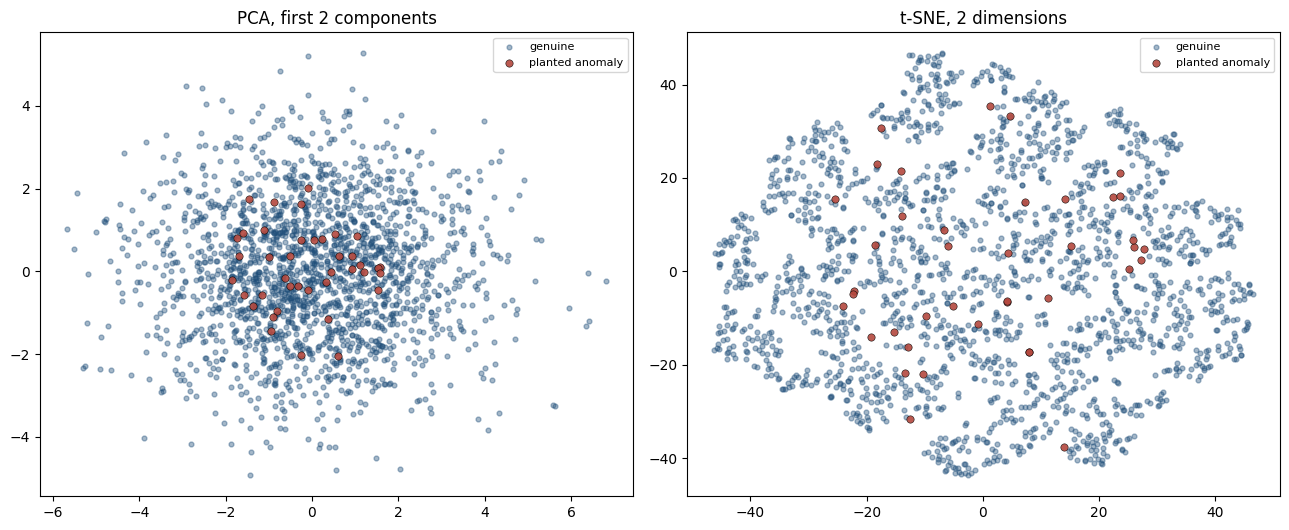

In [15]:
pca_2d = PCA(n_components=2).fit_transform(Xs)
tsne_2d = TSNE(n_components=2, perplexity=30, random_state=0, init="pca").fit_transform(Xs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, emb, title in [(ax1, pca_2d, "PCA, first 2 components"), (ax2, tsne_2d, "t-SNE, 2 dimensions")]:
    ax.scatter(emb[~is_anomaly, 0], emb[~is_anomaly, 1], s=12, alpha=.4, color=BLUE, label="genuine")
    ax.scatter(emb[is_anomaly, 0], emb[is_anomaly, 1], s=28, alpha=.9, color=RUST,
               label="planted anomaly", edgecolor="black", linewidth=.4)
    ax.set_title(title)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "pca_tsne_anomalies.png", dpi=150)
plt.show()

In [16]:
for name, emb in [("PCA, 2 components", pca_2d), ("t-SNE", tsne_2d)]:
    middle = emb[~is_anomaly].mean(axis=0)
    d_anomaly = np.linalg.norm(emb[is_anomaly] - middle, axis=1).mean()
    d_genuine = np.linalg.norm(emb[~is_anomaly] - middle, axis=1).mean()
    print(f"{name:<18} mean distance from the middle: anomalies {d_anomaly:.2f}, genuine accounts {d_genuine:.2f}")

PCA, 2 components  mean distance from the middle: anomalies 1.30, genuine accounts 2.20
t-SNE              mean distance from the middle: anomalies 22.16, genuine accounts 30.17


In both pictures the anomalies sit, on average, **closer** to the middle
than genuine accounts do (1.30 against 2.20 on the PCA plot). Flagging the
points at the edge would catch the wrong accounts. The reason is the one
section 6 drew. A fraudulent account's columns were drawn independently, so on
the directions where genuine accounts spread out together its values partly
cancel, and none of them is extreme to begin with (all lie between the genuine
5th and 95th percentiles); its shadow lands near the middle. What gives it away is not its
distance from the middle but how badly the kept components rebuild it, and a
2-D picture has already thrown that information away.

## 8. The predictable mistake

Notebook 01 showed, correctly, that a scatter plot is often the fastest way
to see groups, so reaching for one here is not unreasonable. The mistake is
treating "plot it and look" as the measurement rather than as a first look. An
anomaly is not necessarily far from the middle: here it is far from the
*pattern*, and only a measure built on the pattern, like the reconstruction
error, can see that.

## Summary

- PCA looks for the directions along which the data spreads most: on two
  standardised columns with correlation $r$, the diagonals, with variances
  $1 + r$ and $1 - r$. In general the components are the eigenvectors of the
  covariance matrix, and each eigenvalue is the variance along its component.
- The scree plot recovered the true number of tendencies, 3, from the data:
  93.5% of the variance in three components.
- Fraudulent accounts with every value in the normal range still break the
  relationship between columns. Reconstruction error from three components
  flagged 37 of the 40 (32 to 38 across eight batches).
- On a 2-D picture, PCA's or t-SNE's, the same anomalies sit closer to the
  middle than genuine accounts: looking for points at the edge finds the
  wrong ones.